# Code and data for *"Information-geometry-driven graph sequential growth"*

---

# Part 1: Experiments on the matrix `494_bus` 

## Contents
 - [A. Problem setting](#sec1A)
 - [B. Standalone method execution (illustration)](#sec1B)
 - [C. Experiments of the manuscript (Section 6.1)](#sec1C)

<a id="sec1A"></a>
## A. Problem setting 

In [1]:
import numpy as np
from scipy.io import mmread
import matplotlib.pyplot as plt

import all_solvers as sol
import all_experiments as exp

The file `494_bus.mtx` is provided in the `Data` folder; it can be found on [Matrix Market](https://math.nist.gov/MatrixMarket/data/Harwell-Boeing/psadmit/494_bus.html), for instance. 

Below, we consider the second $50\times 50$ diagonal block of the matrix `494_bus` (so, $d=50$). 
We compute its inverse and normalise it (covariance to correlation); the resulting matrix is used as the 
the true covariance $\boldsymbol{\Sigma}$ (observe that $\boldsymbol{\Sigma}$ is a correlation matrix); 
$\boldsymbol{\Theta}=\boldsymbol{\Sigma}^{-1}$ is the true precision. 
The underlying graph has $m=30$ edges. 

In [2]:
## Load full 494_bus matrix
bus_494_sparse = mmread('Data/494_bus.mtx', spmatrix=False)
bus_494 = np.array(bus_494_sparse.todense())

## Extract a principal submatrix 
dim = 50
sub_bus_494 = bus_494[50:(50+dim),50:(50+dim)]

## Identify true edges
nb_true_edge, true_edge = sol.compute_number_edges(sub_bus_494)
true_ED = np.array(true_edge)

## Maximum edge capacity
M_edge = int((dim-1) * dim / 2)

## Compute inverse
inv_sub_bus_494 = np.linalg.inv(sub_bus_494)

## Cov to Corr to define true covariance 
sqrt_diag_XX = np.sqrt(np.diag(inv_sub_bus_494))
true_cov = inv_sub_bus_494 / np.outer(sqrt_diag_XX, sqrt_diag_XX) # is a correlation 

## True precision
true_prec = sub_bus_494 * np.outer(sqrt_diag_XX, sqrt_diag_XX)

## True pcorr
true_pcorr = sol.prec_to_pcorr(true_prec)

## Print information
buf = 'Dimension d = %d' % (dim) ; print(buf)
buf = 'Maximum edge capacity M = %d' % (M_edge) ; print(buf)
buf = 'Number of true edges m = %d' % (nb_true_edge) ; print(buf)

Dimension d = 50
Maximum edge capacity M = 1225
Number of true edges m = 30


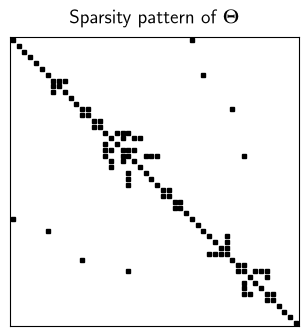

In [3]:
## Plot sparsity pattern of true_prec
plt.figure(figsize=(3.75,3.75))
plt.rcParams.update({"text.usetex": True, "text.latex.preamble": r"\usepackage{amsmath}"}) # LaTeX rendering
plt.spy(true_prec, markersize=3, color='black')
plt.title(r"Sparsity pattern of $\boldsymbol{\Theta}$", fontsize=14, pad=10)
plt.xticks([]); plt.yticks([]) # Removes axis tick numbers 
plt.show()

<a id="sec1B"></a>
## B. Standalone method execution (illustration)

In this section, we illustrate how each graph-recovery strategy (GS, GSL, BBI, BFCI, Prec, PCorr and Glasso) can be applied independently. 

We generate an i.i.d. $N(0,\boldsymbol{\Sigma})$ sample of size $n_{\mathrm{samp}}$, and use this sample to compute the (biased) sample covariance $\hat{\boldsymbol{\Sigma}}$. We then set $\mathbf{S}=\hat{\boldsymbol{\Sigma}}+\mathrm{mean}(\mathrm{diag}(\hat{\boldsymbol{\Sigma}}))\rho\mathbf{I}_{d}$, with $\rho=10^{-6}$ (variable `RP_coeff`).  

In [4]:
## Generate n_samp realisations
rng = np.random.default_rng(seed=1234)
n_samp = 90              # sample size 
RP_coeff = 1e-6          # ridge penalty coeff rho

mean_vector = np.zeros(dim) # zero mean
realisations = rng.multivariate_normal(mean_vector, true_cov, size=n_samp, method='cholesky')

## Compute matrix S and related prec and pcorr
Sigma_hat = (realisations.T @ realisations) / n_samp  
RP_val = np.mean(np.diag(Sigma_hat)) * RP_coeff
S_test = Sigma_hat + RP_val * np.eye(dim)     # matrix S

The cell below computes the full growths produced by `GS_solver`, `GSL_solver` and `BBI_solver` (relaxed coordinate descents).   

In [6]:
## First call of the solvers requires compilation.  
## For representative timing, this cell needs to be run twice. 
print('## GS run')
%time GS = sol.GS_solver(S=S_test, max_iter=M_edge, true_P=true_prec, \
                         activ_mul=0.3, activ_add=10, tau_improv=1e-3) 

print('## GSL run')
%time GSL = sol.GSL_solver(S=S_test, max_iter=M_edge, true_P=true_prec, \
                           activ_mul=0.3, activ_add=10, tau_improv=1e-3) 

print('## BBI run')
%time BBI = sol.BBI_solver(S=S_test, max_iter=M_edge, true_P=true_prec, \
                           activ_mul=0.3, activ_add=10, tau_improv=1e-3) 

## GS run
CPU times: user 791 ms, sys: 2.2 ms, total: 793 ms
Wall time: 793 ms
## GSL run
CPU times: user 766 ms, sys: 2.13 ms, total: 768 ms
Wall time: 767 ms
## BBI run
CPU times: user 2.24 s, sys: 5.71 ms, total: 2.24 s
Wall time: 2.24 s


We next run `BFCI_solver`; for speed, we only perform a partial growth, up to $k=300$ edges (computing the full growth can take a few minutes).

In [7]:
print('## BFCI run (k_max=300)')
%time BFCI = sol.BFCI_solver(S=S_test, max_iter=300, \
                             true_P=true_prec, \
                             activ_mul=0.3, activ_add=10, tau_improv=1e-3) 

## BFCI run (k_max=300)
CPU times: user 34.1 s, sys: 87.6 ms, total: 34.2 s
Wall time: 34.2 s


We finally compute the full growth induced by the naive magnitude-based methods Prec (precision magnitude)
and PCorr (partial-correlation magnitude), and we approximate the regularisation path of Glasso using `n_glasso=500` points uniformly spaced over the interval $\big[0,\max_{i\neq j}|\mathbf{S}_{i,j}|\big]$.

In [8]:
## Prec and PCorr
prec_test = np.linalg.inv(S_test)             # sample precision, i.e. inverse of S            
pcorr_test = sol.prec_to_pcorr(prec_test)     # sample pcorr

Prec = sol.magnitude_xtr(P_mat=prec_test, k=M_edge, true_P=true_prec)
PCorr = sol.magnitude_xtr(P_mat=pcorr_test, k=M_edge, true_P=true_prec) 

## Glasso
Glasso_ROCx = sol.Glasso_ROC(S=S_test, true_P=true_prec, n_glasso=500)

The cell below computes the resulting ROC and precision-recall curves, and plots them. 

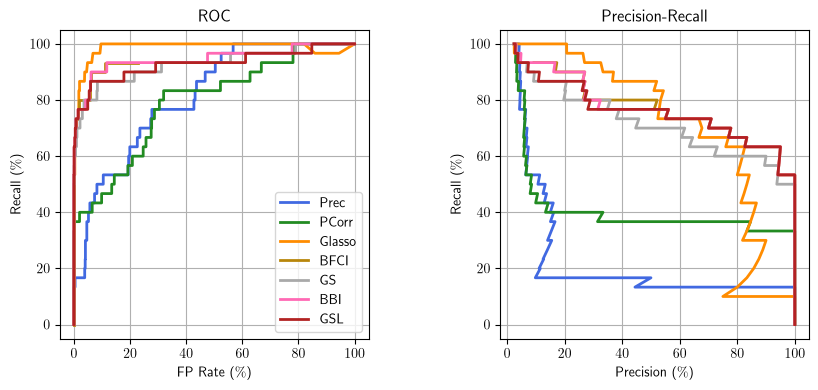

In [9]:
## Compute ROC and precision-recall curves (append limit values)
GSL_ROC = sol.compute_ROC(nb_true_edge, M_edge, Run=GSL)
GSL_ROC = (np.concatenate(([100], GSL_ROC[0])), np.concatenate(([0], GSL_ROC[1])), np.concatenate(([0], GSL_ROC[2])) ) 

GS_ROC = sol.compute_ROC(nb_true_edge, M_edge, Run=GS)
GS_ROC = (np.concatenate(([100], GS_ROC[0])), np.concatenate(([0], GS_ROC[1])), np.concatenate(([0], GS_ROC[2])) ) 

BBI_ROC = sol.compute_ROC(nb_true_edge, M_edge, Run=BBI)
BBI_ROC = (np.concatenate(([100], BBI_ROC[0])), np.concatenate(([0], BBI_ROC[1])), np.concatenate(([0], BBI_ROC[2])) ) 

BFCI_ROC = sol.compute_ROC(nb_true_edge, M_edge, Run=BFCI)
BFCI_ROC = (np.concatenate(([100], BFCI_ROC[0])), np.concatenate(([0], BFCI_ROC[1])), np.concatenate(([0], BFCI_ROC[2])) ) 
 
Prec_ROC = sol.compute_ROC(nb_true_edge, M_edge, Run=Prec) 
Prec_ROC = (np.concatenate(([100], Prec_ROC[0])), np.concatenate(([0], Prec_ROC[1])), np.concatenate(([0], Prec_ROC[2])) )

PCorr_ROC = sol.compute_ROC(nb_true_edge, M_edge, Run=PCorr)
PCorr_ROC = (np.concatenate(([100], PCorr_ROC[0])), np.concatenate(([0], PCorr_ROC[1])), np.concatenate(([0], PCorr_ROC[2])) )

Glasso_ROC = (np.concatenate((Glasso_ROCx[0],[(nb_true_edge/M_edge)*100])), np.concatenate((Glasso_ROCx[1],[100])), np.concatenate((Glasso_ROCx[2],[100])) )

## Gather results
All_run = {'GSL' : GSL_ROC, 
           'BBI' : BBI_ROC, 
           'GS' : GS_ROC,
           'BFCI' : BFCI_ROC, 
           'Prec' : Prec_ROC, 
           'PCorr' : PCorr_ROC, 
           'Glasso' : Glasso_ROC }

methods = ['Prec', 'PCorr', 'Glasso', 'BFCI', 'GS', 'BBI', 'GSL']
color_list = {'GSL': 'firebrick',
              'Glasso': 'darkorange',
              'PCorr': 'forestgreen',
              'Prec': 'royalblue',
              'BBI': 'hotpink',
              'BFCI': 'darkgoldenrod',
              'GS': 'darkgrey'}

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(9, 4))

## Plot ROC and Precision-Recall
for label in methods:
    ROC = All_run[label] 
    axes[0].plot(ROC[2], ROC[1], color=color_list[label], linewidth=2, label=label)
    axes[1].plot(ROC[0], ROC[1], color=color_list[label], linewidth=2)


## Subplot formatting
axes[0].set_title(r'ROC')
axes[0].set_xlabel(r'FP Rate ($\%$)')
axes[0].set_ylabel(r'Recall ($\%$)')
axes[0].legend(loc='lower right')
axes[0].grid(True)
axes[0].set_box_aspect(1)

axes[1].set_title(r'Precision-Recall')
axes[1].set_xlabel(r'Precision ($\%$)')
axes[1].set_ylabel(r'Recall ($\%$)')
axes[1].grid(True)
axes[1].set_box_aspect(1)

plt.tight_layout()
plt.show()

<a id="sec1C"></a>
## C. Experiments of the manuscript (Section 6.1)  

> **Computational note:** Numerically, and for similar approximate-full-correction parameters, computing a BFCI growth is significantly more demanding than computing a GS, GSL or BBI growth. Experiments involving multiple full BFCI growths are relatively demanding (for $d=50$, each full BFCI growth can take a few minutes). To run a ROC-curve experiment without BFCI, remove `BFCI` from the `methods` input list of the function `run_experiment_ROC`.  

### Experiment for Figure 1

In [10]:
## 1. Run Figure 1 experiment (100 reps for GS/GSL/BBI, 10 reps for BFCI)
## Each BFCI run can take a few minutes.  
results_fig1 = exp.run_experiment_ROC(
    true_cov = true_cov,
    true_P = true_prec,
    n_samples_list = [30, 90, 160],
    n_reps = 100,
    n_reps_BFCI = 10,
    #methods = ['BFCI', 'GS', 'BBI', 'GSL'],  # run with BFCI
    methods = ['GS', 'BBI', 'GSL'],           # run without BFCI
    activ_mul = 0.3,
    activ_add = 10,
    tau_improv = 1e-3,
    RP_coeff = 1e-6,
    n_jobs=-1,         # allocate maximum number of threads
    seed=1
)

Starting parallel ROC experiment: d=50, reps=100, 
methods=['GS', 'BBI', 'GSL'], n_jobs=-1


Sample size n = 160: 100%|███████████████████| 100/100 [00:35<00:00,  2.83it/s]


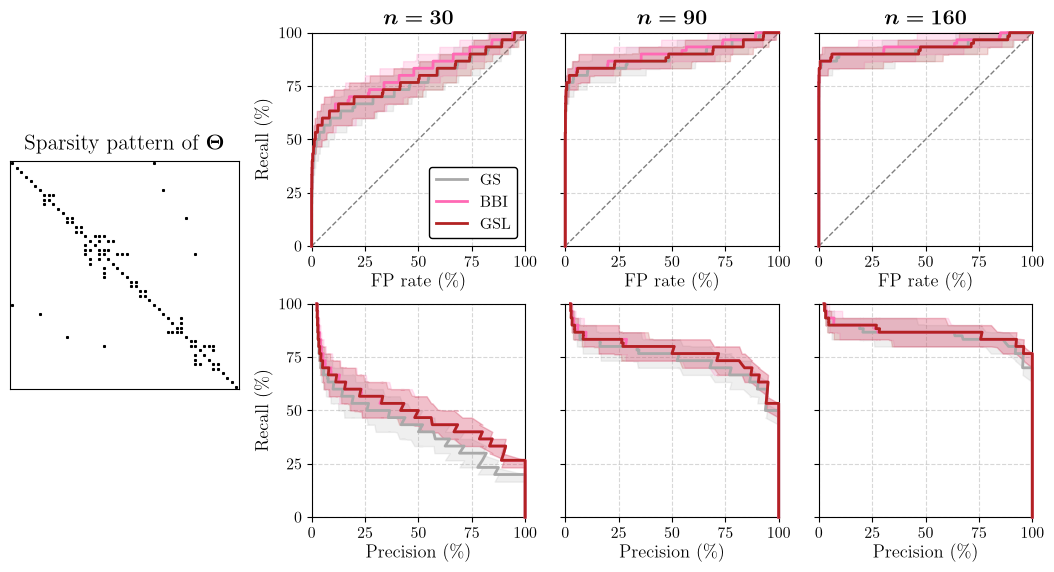

In [12]:
# 2. Render Figure 1
fig1 = exp.plot_figure_1(
    results=results_fig1,
    true_P=true_prec,
    n_samples_list=[30, 90, 160] 
    #save_path="Figures/Figure_1.pdf"
)

### Experiment for Figure 2

In [13]:
## 1. Run Figure 2 experiment (100 reps)
results_fig2 = exp.run_experiment_ROC(
    true_cov=true_cov,
    true_P=true_prec,
    n_samples_list=[30, 90, 160],
    n_reps=100,
    methods=['Prec', 'PCorr', 'Glasso', 'GSL'],
    activ_mul=0.3,
    activ_add=10,
    tau_improv=1e-3,
    n_glasso=500,
    n_jobs=-1,
    seed=1
)

Starting parallel ROC experiment: d=50, reps=100, 
methods=['Prec', 'PCorr', 'Glasso', 'GSL'], n_jobs=-1


Sample size n = 160: 100%|███████████████████| 100/100 [00:37<00:00,  2.67it/s]


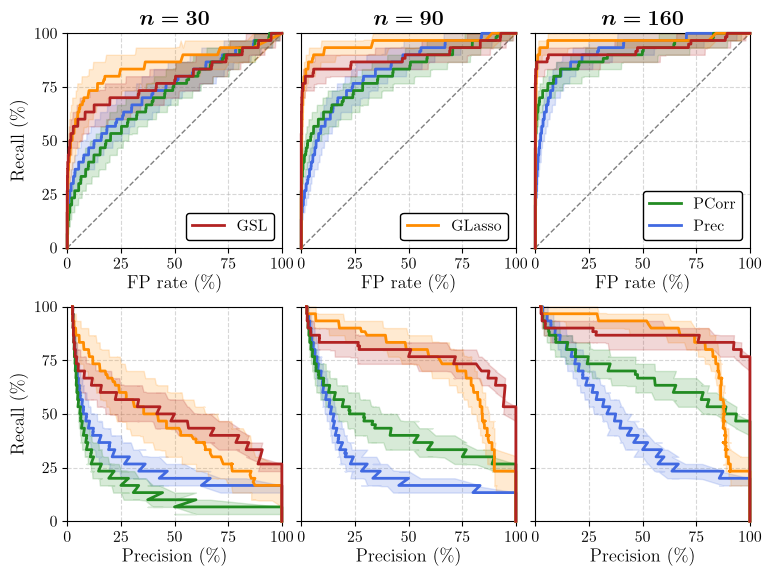

In [14]:
## 2. Render Figure 2
fig = exp.plot_figure_2(
    results=results_fig2, 
    n_samples_list=[30, 90, 160]
    #save_path="Figures/Figure_2.pdf"
)

In [15]:
## Identify crossing between GSL and Glasso precision-recall curves
print("--- First Crossing (GSL Recall(P) < GLasso Recall(P)) ---")

for n_val in [30, 90, 160]:
    gsl_p = np.median(results_fig2[n_val]['GSL']['prec'], axis=0)
    gsl_r = np.median(results_fig2[n_val]['GSL']['rec'], axis=0)
    
    gl_p  = np.median(results_fig2[n_val]['Glasso']['prec'], axis=0)
    gl_r  = np.median(results_fig2[n_val]['Glasso']['rec'], axis=0)

    # 1. Interpolate GLasso recall at GSL precision points
    sort_idx = np.argsort(gl_p)
    gl_r_at_gsl_p = np.interp(gsl_p, gl_p[sort_idx], gl_r[sort_idx])

    # 2. Find index where GSL recall drops below GLasso recall
    diff = gsl_r - gl_r_at_gsl_p
    first_below = np.where(diff[1:] < 0)[0]
    
    # GSL step index k corresponds directly to the edge count
    k_est = first_below[0] + 1 if len(first_below) > 0 else 1

    P_star = gsl_p[k_est]
    R_star = gsl_r[k_est]

    print(f"n = {n_val:3d} | Precision P* = {P_star:5.1f}% | Recall R* = {R_star:5.1f}% | Est. Edges k* = {k_est:3d}")

--- First Crossing (GSL Recall(P) < GLasso Recall(P)) ---
n =  30 | Precision P* =  27.9% | Recall R* =  56.7% | Est. Edges k* =  61
n =  90 | Precision P* =  59.0% | Recall R* =  76.7% | Est. Edges k* =  39
n = 160 | Precision P* =  66.7% | Recall R* =  86.7% | Est. Edges k* =  39


### Experiment for Figure 3

In [16]:
## 1. Run Figure 3 experiment (100 reps, n=30, k=30)
results_fig3 = exp.run_experiment_fig3(
    true_cov=true_cov,
    true_P=true_prec,
    n_samples=30,
    k_edges=30,
    n_reps=500,
    methods=['GSL', 'PCorr', 'Prec'],
    activ_mul=0.3,
    activ_add=10,
    tau_improv=1e-3,
    RP_coeff=1e-6,
    seed=1
)

Starting experiment: d=50, reps=500, RP_coeff=1e-06


Sample size n = 30: 100%|██████████████████| 500/500 [00:00<00:00, 2340.90it/s]


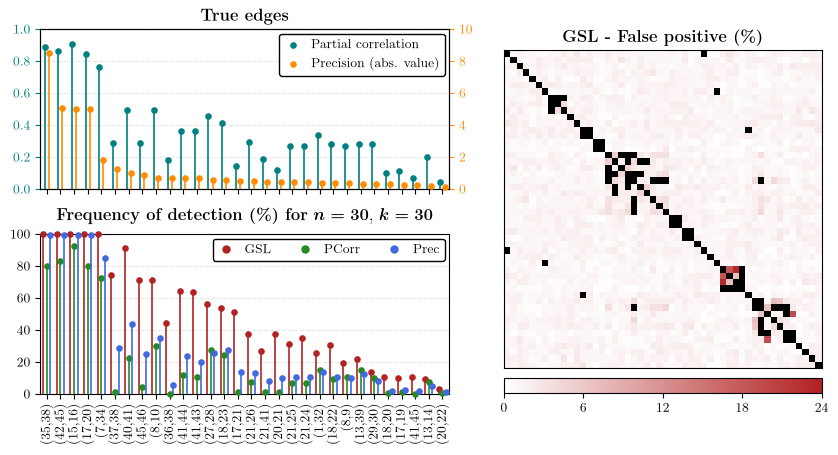

In [17]:
## 2. Render Figure 3
fig3 = exp.plot_figure_3(
    results=results_fig3 
    #save_path="Figures/Figure_3.pdf"
)

### Experiment for Figure 4

In [18]:
## 1. Execute Figure 4 experiment (n=90, 500 reps, full growth k=1225)
results_fig4 = exp.run_experiment_fig4(
    true_cov=true_cov,
    true_P=true_prec,
    n_samples=90,
    max_iter=M_edge,
    n_reps=500,
    activ_mul=0.3,
    activ_add=10,
    tau_improv=1e-3,
    RP_coeff=1e-6,
    n_jobs=-1,
    seed=555
)

Starting Figure 4 experiment: d=50, n=90, max_iter=1225, reps=500, n_jobs=-1


Sample size n = 90: 100%|████████████████████| 500/500 [00:46<00:00, 10.65it/s]


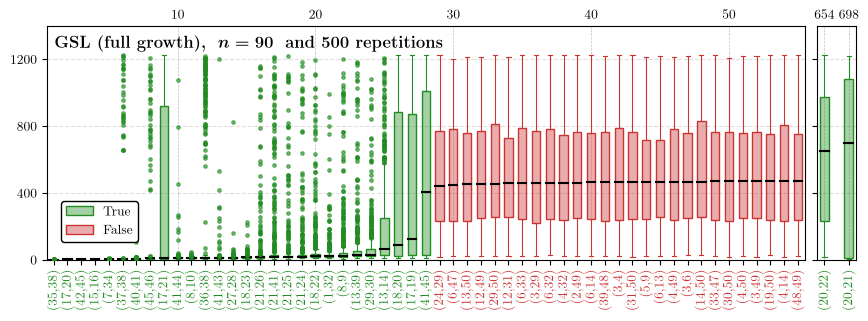

In [19]:
## 2. Render Figure 4
fig4 = exp.plot_figure_4(
    results=results_fig4
    #save_path="Figures/Figure_4.pdf"
)

### Experiment for Figure 5 

In [20]:
## 1. Run Figure 5 experiment (GSL_solver)
results_fig5 = exp.run_experiment_fig5(
    true_cov=true_cov,
    true_P=true_prec,
    n_samples=90,
    max_iter=300,
    n_reps=100,
    taus=[1e-1, 1e-3, 1e-5],
    activ_mul=10,
    activ_add=10,
    RP_coeff=1e-6,
    seed=555
)

Starting Figure 5 Monte Carlo experiment: d=50, n=90, max_iter=300, reps=100, n_jobs=-1


Monte Carlo reps (n=90): 100%|██████████████| 100/100 [00:00<00:00, 117.87it/s]


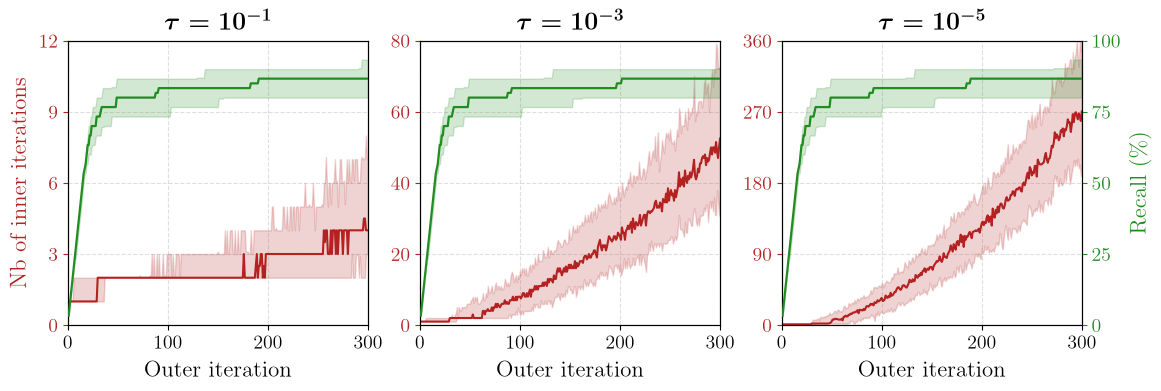

In [21]:
## 2. Render Figure 5
fig5 = exp.plot_figure_5(
    results=results_fig5
    #save_path="Figures/Figure_5.pdf"
)